# BCCC-DeFiFraudTrans-2025 — Data Exploration

**Paper:** A Synthetic Data Generation and Machine Learning Framework for Detecting Malicious Activities in DeFi  
**Author:** Frank Junior Hoza Longfor (FAMU)

**Goal of this notebook:** understand the dataset *as it actually is* before building the pipeline. We confirm the file structure, the real feature columns and their types, the fraud/legitimate class balance, and the distributions of key features. Nothing here assumes column names — we discover them from the files.

> This is notebook 1 of 4. Its findings determine how notebooks 2–4 (preprocessing, generation, classification) are written. Fill in the findings summary at the bottom once you've run it.

## 1. Setup & loading the data

Pick **one** of the loading options below depending on where your data is. The dataset ships as JSON files (per wallet / per transaction), so we handle both a folder-of-JSON and a single CSV/JSON, whichever you have.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/SDG_paper/data/BCC/DeFiTransLyzer_fraud.csv'

Mounted at /content/drive


In [ ]:
import os, json, glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

print('DATA_PATH:', DATA_PATH)
print('Exists:', os.path.exists(DATA_PATH))
print('Is directory:', os.path.isdir(DATA_PATH))

DATA_PATH: /content/drive/MyDrive/SDG_paper/data/BCC/DeFiTransLyzer_fraud.csv
Exists: True
Is directory: False


## 2. Discover the file structure

We don't yet know whether the data is one big file or thousands of small JSONs. This cell inventories what's actually there.

In [ ]:
if os.path.isdir(DATA_PATH):
    # Walk the directory and count files by extension
    ext_counts = {}
    sample_files = {}
    for root, _, filenames in os.walk(DATA_PATH):
        for fn in filenames:
            ext = os.path.splitext(fn)[1].lower()
            ext_counts[ext] = ext_counts.get(ext, 0) + 1
            if ext not in sample_files:
                sample_files[ext] = os.path.join(root, fn)
    print('File counts by extension:')
    for ext, n in sorted(ext_counts.items(), key=lambda x: -x[1]):
        print(f'  {ext or "(none)"}: {n}')
    print('\nExample file of each type:')
    for ext, path in sample_files.items():
        print(f'  {ext}: {path}')
else:
    print('Single file. Size: {:.1f} MB'.format(os.path.getsize(DATA_PATH) / 1e6))

Single file. Size: 104.9 MB


In [ ]:
# Peek at ONE json file to understand its shape (keys, nesting) before loading everything.
# Edit the path if needed based on the inventory above.
example_json = None
if os.path.isdir(DATA_PATH):
    jsons = glob.glob(os.path.join(DATA_PATH, '**', '*.json'), recursive=True)
    print(f'Found {len(jsons)} JSON files.')
    if jsons:
        example_json = jsons[0]
elif DATA_PATH.endswith('.json'):
    example_json = DATA_PATH

if example_json:
    with open(example_json) as f:
        sample = json.load(f)
    print('Example file:', example_json)
    print('Top-level type:', type(sample).__name__)
    if isinstance(sample, dict):
        print('Top-level keys:', list(sample.keys())[:30])
    elif isinstance(sample, list):
        print('List length:', len(sample))
        if sample and isinstance(sample[0], dict):
            print('Keys of first record:', list(sample[0].keys())[:30])
    print('\nRaw preview:')
    print(json.dumps(sample, indent=2)[:1500])

## 3. Load into a DataFrame

**This cell depends on what you found above.** Three common cases are handled. Uncomment the one that matches your data, adjust if the structure is nested differently, and leave the others commented.

In [ ]:
df = None

# --- Case 1: a single CSV ---
df = pd.read_csv(DATA_PATH)

# --- Case 2: a single JSON that is a list of records ---
# df = pd.read_json(DATA_PATH)

# --- Case 3: a folder of per-record JSON files (one dict each) ---
# records = []
# for p in glob.glob(os.path.join(DATA_PATH, '**', '*.json'), recursive=True):
#     with open(p) as f:
#         obj = json.load(f)
#     if isinstance(obj, dict):
#         records.append(obj)
#     elif isinstance(obj, list):
#         records.extend(obj)
# df = pd.json_normalize(records)   # flattens nested fields

assert df is not None, 'Uncomment and adjust the loading case that matches your data.'
print('Loaded shape:', df.shape)
df.head()

/tmp/ipykernel_5321/2414077462.py:4: DtypeWarning: Columns (26,28,132,133,134) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


Loaded shape: (88793, 171)


,Unnamed: 0,address,hash,flag,length_transaction_hash,length_to,is_contract_creation,status,log_removed,block_number,gas_used,length_from,index,gas_efficiency,value,chain_id,message,total_gas_cost,gas_per_log_event,log_index,event_activity_flag,normalized_token_transfer,effective_gas_price,cumulative_gas_used,is_same_address,gas_price_ratio,token_transfer_amount,length_log,Error!,log_count,num_transaction,duration_seconds,number_of_errors,error_rate,gas_used.gas_used_summation,gas_used.gas_used_average,gas_used.gas_used_median,gas_used.gas_used_standard_deviation,gas_used.gas_used_maximum_val,gas_used.gas_used_minimum_val,gas_used.gas_used_variance,gas_used.gas_used_range_value,gas_used.gas_used_skewness,gas_used.gas_used_mode,gas_used.gas_used_coefficient_of_variation,gas_prices.gas_prices_summation,gas_prices.gas_prices_average,gas_prices.gas_prices_median,gas_prices.gas_prices_standard_deviation,gas_prices.gas_prices_maximum_val,gas_prices.gas_prices_minimum_val,gas_prices.gas_prices_variance,gas_prices.gas_prices_range_value,gas_prices.gas_prices_skewness,gas_prices.gas_prices_mode,gas_prices.gas_prices_coefficient_of_variation,cumulativeGasUsed.cumulativeGasUsed_summation,cumulativeGasUsed.cumulativeGasUsed_average,cumulativeGasUsed.cumulativeGasUsed_median,cumulativeGasUsed.cumulativeGasUsed_standard_deviation,cumulativeGasUsed.cumulativeGasUsed_maximum_val,cumulativeGasUsed.cumulativeGasUsed_minimum_val,cumulativeGasUsed.cumulativeGasUsed_variance,cumulativeGasUsed.cumulativeGasUsed_range_value,cumulativeGasUsed.cumulativeGasUsed_skewness,cumulativeGasUsed.cumulativeGasUsed_mode,cumulativeGasUsed.cumulativeGasUsed_coefficient_of_variation,values.values_summation,values.values_average,values.values_median,values.values_standard_deviation,values.values_maximum_val,values.values_minimum_val,values.values_variance,values.values_range_value,values.values_skewness,values.values_mode,values.values_coefficient_of_variation,nonce.nonce_summation,nonce.nonce_average,nonce.nonce_median,nonce.nonce_standard_deviation,nonce.nonce_maximum_val,nonce.nonce_minimum_val,nonce.nonce_variance,nonce.nonce_range_value,nonce.nonce_skewness,nonce.nonce_mode,nonce.nonce_coefficient_of_variation,number_of_from_address,number_of_unique_from_address,number_of_to_address,number_of_unique_to_address,erc_20_TokenAddress,erc_20_TokenName,erc_20_TokenSymbol,erc_20_Name_Length,erc_20_Symbol_Length,erc_20_Name_Uppercase_Ratio,erc_20_Symbol_Is_Uppercase,erc_20_Name_Contains_Token,erc_20_Symbol_Contains_XYZ,erc_20_Symbol_Starts_With_X,erc_20_Name_Starts_With_The,erc_20_Name_Num_Words,erc_20_Name_Has_Special,erc_20_Symbol_Has_Special,erc_20_Name_Is_Alnum,erc_20_Symbol_Is_Alnum,erc_20_Name_Has_Digit,erc_20_Symbol_Has_Digit,erc_20_Symbol_Same_As_Name,erc_20_Symbol_End_Is_Digit,erc_20_Symbol_All_Same_Char,erc_20_Name_All_Same_Char,erc_20_TokenDivisor,erc_20_TokenQuantity,erc_20_Normalized_Quantity,erc_20_Log_Quantity,erc_20_Log_Normalized_Quantity,erc_20_Is_Zero_Quantity,erc_20_Is_Zero_Divisor,erc_20_Decimals_Above_10,erc_20_Quantity_Is_Int,erc_20_Unique_Chars_Name,erc_20_Unique_Chars_Symbol,erc_20_Name_Lowercase_Count,erc_20_Symbol_Lowercase_Count,erc_20_Name_Num_Uppercase,erc_20_Symbol_Num_Uppercase,erc_20_Name_Entropy,erc_20_Symbol_Entropy,erc_721_TokenAddress,erc_721_TokenName,erc_721_TokenSymbol,erc_721_Name_Length,erc_721_Symbol_Length,erc_721_Name_Uppercase_Ratio,erc_721_Symbol_Is_Uppercase,erc_721_Name_Contains_Token,erc_721_Symbol_Contains_XYZ,erc_721_Symbol_Starts_With_X,erc_721_Name_Starts_With_The,erc_721_Name_Num_Words,erc_721_Name_Has_Special,erc_721_Symbol_Has_Special,erc_721_Name_Is_Alnum,erc_721_Symbol_Is_Alnum,erc_721_Name_Has_Digit,erc_721_Symbol_Has_Digit,erc_721_Symbol_Same_As_Name,erc_721_Symbol_End_Is_Digit,erc_721_Symbol_All_Same_Char,erc_721_Name_All_Same_Char,erc_721_TokenDivisor,erc_721_TokenQuantity,erc_721_Normalized_Quantity,erc_721_Log_Quantity,erc_721_Log_Normalized_Quantity,erc_721_Is_Zero_Quantity,erc_721_Is_Zero_Divisor,erc_7

In [ ]:
import os, glob
import pandas as pd
import numpy as np

# Folder that contains BOTH files (fraud + legitimate)
DATA_DIR = '/content/drive/MyDrive/SDG_paper/data/BCC'   # <-- adjust if needed

# Find the data files (csv or json) in that folder
files = []
for ext in ('*.csv', '*.json'):
    files += glob.glob(os.path.join(DATA_DIR, '**', ext), recursive=True)
print('Files found:')
for f in files:
    print('  ', f)

def load_one(path):
    if path.endswith('.csv'):
        return pd.read_csv(path)
    else:
        try:
            return pd.read_json(path)
        except ValueError:
            return pd.read_json(path, lines=True)   # JSON-lines fallback

# Infer label from filename: anything mentioning 'fraud'/'malicious'/'illicit' -> 1, else 0
def infer_label(path):
    name = os.path.basename(path).lower()
    if any(k in name for k in ['fraud', 'malicious', 'illicit', 'bad']):
        return 1
    if any(k in name for k in ['legit', 'benign', 'normal', 'good', 'clean']):
        return 0
    return None   # couldn't tell

frames = []
for f in files:
    lbl = infer_label(f)
    part = load_one(f)
    part['label'] = lbl
    print(f'{os.path.basename(f)}: {len(part):,} rows -> label={lbl}')
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print('\nCombined shape:', df.shape)
print('\nLabel counts:')
print(df['label'].value_counts(dropna=False))

Files found:
   /content/drive/MyDrive/SDG_paper/data/BCC/DeFiTransLyzer_fraud.csv
   /content/drive/MyDrive/SDG_paper/data/BCC/DeFiTransLyzer_legitimate.csv


/tmp/ipykernel_5321/1512817707.py:18: DtypeWarning: Columns (26,28,132,133,134) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


DeFiTransLyzer_fraud.csv: 88,793 rows -> label=1


/tmp/ipykernel_5321/1512817707.py:18: DtypeWarning: Columns (28,93,94,95,132,133,134) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


DeFiTransLyzer_legitimate.csv: 938,074 rows -> label=0

Combined shape: (1026867, 172)

Label counts:
label
0    938074
1     88793
Name: count, dtype: int64


## 4. Columns, types, and missing values

This is the core of the notebook: the **real** feature list. Compare it against what the paper claims (79 features; the paper's tables don't fully reconcile, so your files are the source of truth).

In [ ]:
print('Number of columns:', df.shape[1])
print('Number of rows:', df.shape[0])

info = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(2),
})
info

Number of columns: 171
Number of rows: 88793


,dtype,n_unique,n_missing,pct_missing
Unnamed: 0,int64,88793,0,0.0
address,object,1762,0,0.0
hash,object,88793,0,0.0
flag,int64,1,0,0.0
length_transaction_hash,int64,1,0,0.0
...,...,...,...,...
erc_721_Symbol_Lowercase_Count,int64,3,0,0.0
erc_721_Name_Num_Uppercase,int64,5,0,0.0
erc_721_Symbol_Num_Uppercase,int64,3,0,0.0
erc_721_Name_Entropy,float64,7,0,0.0


In [ ]:
# Separate likely-numeric from likely-categorical columns (helps later preprocessing)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
non_numeric_cols = [c for c in df.columns if c not in numeric_cols]
print(f'Numeric columns ({len(numeric_cols)}):')
print(numeric_cols)
print(f'\nNon-numeric columns ({len(non_numeric_cols)}):')
print(non_numeric_cols)

Numeric columns (158):
['Unnamed: 0', 'flag', 'length_transaction_hash', 'length_to', 'log_removed', 'block_number', 'gas_used', 'length_from', 'index', 'gas_efficiency', 'value', 'chain_id', 'total_gas_cost', 'gas_per_log_event', 'log_index', 'event_activity_flag', 'normalized_token_transfer', 'effective_gas_price', 'cumulative_gas_used', 'is_same_address', 'gas_price_ratio', 'length_log', 'log_count', 'num_transaction', 'duration_seconds', 'number_of_errors', 'error_rate', 'gas_used.gas_used_summation', 'gas_used.gas_used_average', 'gas_used.gas_used_median', 'gas_used.gas_used_standard_deviation', 'gas_used.gas_used_maximum_val', 'gas_used.gas_used_minimum_val', 'gas_used.gas_used_variance', 'gas_used.gas_used_range_value', 'gas_used.gas_used_skewness', 'gas_used.gas_used_mode', 'gas_used.gas_used_coefficient_of_variation', 'gas_prices.gas_prices_summation', 'gas_prices.gas_prices_average', 'gas_prices.gas_prices_median', 'gas_prices.gas_prices_standard_deviation', 'gas_prices.gas_p

## 5. Find the label column & class balance

The single most important thing for this project. We try to auto-detect the fraud/legitimate label, then confirm the ratio against the paper's reported 88,793 fraud / 938,074 legitimate (~1:10.6 at transaction level).

In [ ]:
# Guess the label column by common names — EDIT if yours differs
candidate_label_names = ['label', 'is_fraud', 'fraud', 'class', 'target', 'y', 'Label', 'isFraud']
label_col = next((c for c in candidate_label_names if c in df.columns), None)

if label_col is None:
    # Fallback: show low-cardinality columns as label candidates
    print('No obvious label column. Low-cardinality columns (possible labels):')
    for c in df.columns:
        if df[c].nunique() <= 5:
            print(f'  {c}: {df[c].unique()[:5]}')
    # label_col = 'EDIT_ME'
else:
    print('Detected label column:', label_col)
    counts = df[label_col].value_counts(dropna=False)
    print('\nClass counts:')
    print(counts)
    print('\nClass proportions:')
    print((df[label_col].value_counts(normalize=True) * 100).round(2))
    if len(counts) == 2:
        maj, mn = counts.max(), counts.min()
        print(f'\nImbalance ratio ~ 1:{maj/mn:.1f}')

No obvious label column. Low-cardinality columns (possible labels):
  flag: [1]
  length_transaction_hash: [66]
  length_to: [42  0]
  is_contract_creation: [False]
  status: ['Failed']
  log_removed: [0]
  length_from: [42]
  chain_id: [1 0]
  message: ['NOTOK']
  gas_per_log_event: [0]
  log_index: [nan]
  event_activity_flag: [0 1]
  normalized_token_transfer: [0]
  is_same_address: [0 1]
  gas_price_ratio: [1 0]
  Error!: [0 '0' 'One or more errors occurred.']
  log_count: [0]
  erc_20_Symbol_Is_Uppercase: [1 0]
  erc_20_Name_Contains_Token: [0 1]
  erc_20_Symbol_Contains_XYZ: [0 1]
  erc_20_Symbol_Starts_With_X: [0 1]
  erc_20_Name_Starts_With_The: [0 1]
  erc_20_Name_Has_Special: [0 1]
  erc_20_Symbol_Has_Special: [1 0]
  erc_20_Name_Is_Alnum: [1 0]
  erc_20_Symbol_Is_Alnum: [0 1]
  erc_20_Name_Has_Digit: [0 1]
  erc_20_Symbol_Has_Digit: [0 1]
  erc_20_Symbol_Same_As_Name: [0 1]
  erc_20_Symbol_End_Is_Digit: [0 1]
  erc_20_Symbol_All_Same_Char: [0 1]
  erc_20_Name_All_Same_Char: 

In [ ]:
# Visualize class balance
if label_col:
    ax = df[label_col].value_counts().plot(kind='bar', color=['#2E75B6', '#D9534F'])
    ax.set_title('Class distribution')
    ax.set_xlabel(label_col); ax.set_ylabel('count')
    plt.tight_layout(); plt.show()

## 6. Distributions of key numeric features

We expect heavy right-skew in value/gas features (confirms the need for log-scaling before generation). We also compare fraud vs. legitimate to see which features carry signal.

In [ ]:
# Summary statistics for numeric features
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,88793.0,328375.920940,451653.570211,0.0,22198.0,44396.0,1004668.0,1.026866e+06
flag,88793.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.000000e+00
length_transaction_hash,88793.0,66.000000,0.000000,66.0,66.0,66.0,66.0,6.600000e+01
length_to,88793.0,41.901141,2.035278,0.0,42.0,42.0,42.0,4.200000e+01
log_removed,88793.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000e+00
...,...,...,...,...,...,...,...,...
erc_721_Symbol_Lowercase_Count,88793.0,0.118084,0.354951,0.0,0.0,0.0,0.0,5.000000e+00
erc_721_Name_Num_Uppercase,88793.0,0.701553,1.290621,0.0,0.0,0.0,0.0,8.000000e+00
erc_721_Symbol_Num_Uppercase,88793.0,0.700078,1.276912,0.0,0.0,0.0,0.0,4.000000e+00
erc_721_Name_Entropy,88793.0,0.854367,1.557312,0.0,0.0,0.0,0.0,4.056021e+00


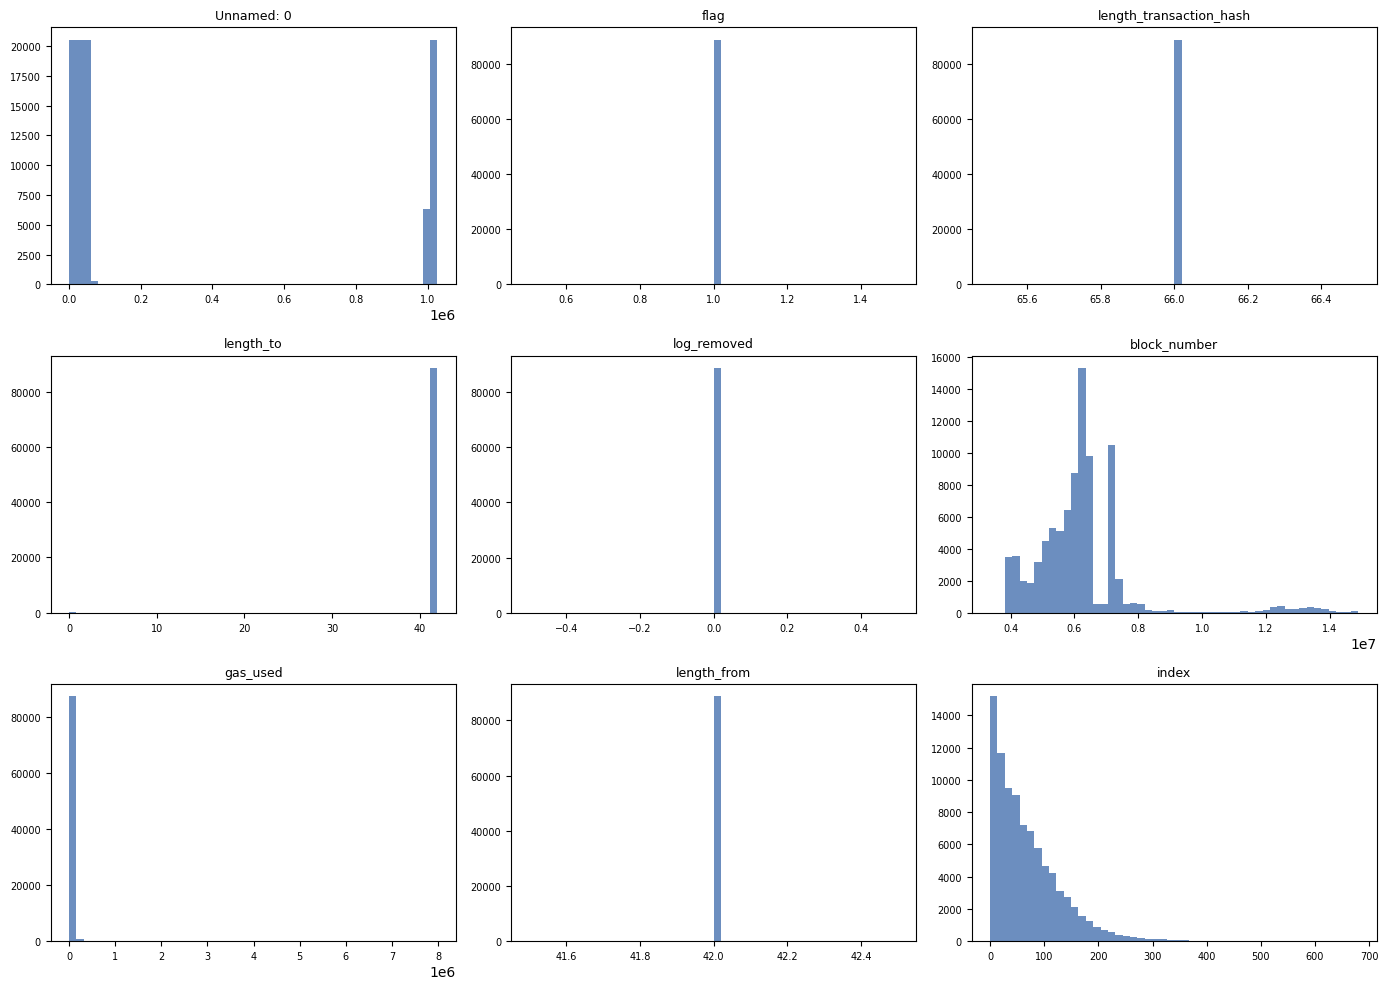

In [ ]:
# Histograms of the first handful of numeric features (log scale on x where skewed)
cols_to_plot = numeric_cols[:9]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), cols_to_plot):
    vals = df[col].dropna()
    ax.hist(vals, bins=50, color='#6C8EBF')
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(cols_to_plot):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# Skewness — large values (>2 or <-2) indicate columns needing log transform later
if numeric_cols:
    skew = df[numeric_cols].skew().sort_values(ascending=False)
    print('Most skewed numeric features (candidates for log-scaling):')
    print(skew.head(15))

Most skewed numeric features (candidates for log-scaling):
value                            218.890140
values.values_minimum_val        164.923718
total_gas_cost                   115.655764
values.values_mode               109.490892
effective_gas_price              104.094900
values.values_median              96.348886
erc_20_Name_All_Same_Char         72.251604
erc_20_Symbol_All_Same_Char       72.251604
erc_20_TokenQuantity              71.994605
erc_20_Normalized_Quantity        71.994577
is_same_address                   63.507338
length_log                        62.793681
nonce.nonce_minimum_val           60.788476
gas_used.gas_used_minimum_val     48.483574
gas_prices.gas_prices_mode        42.933460
dtype: float64


In [ ]:
# Compare a few features across classes (mean by class) — rough signal check
if label_col and numeric_cols:
    comparison = df.groupby(label_col)[numeric_cols].mean().T
    comparison['abs_diff'] = (comparison.iloc[:, 0] - comparison.iloc[:, 1]).abs()
    print('Feature means by class (sorted by absolute difference):')
    comparison.sort_values('abs_diff', ascending=False).head(15)

In [ ]:
# Leakage check: does any column give away the label by itself?
for col in ['flag', 'status', 'message', 'is_contract_creation', 'error_rate',
            'number_of_errors', 'Error!', 'duration_seconds', 'num_transaction']:
    if col in df.columns:
        print(f'\n=== {col} ===')
        for lbl in [0, 1]:
            top = df[df['label'] == lbl][col].value_counts(dropna=False).head(3)
            print(f'  label={lbl}: {top.to_dict()}')


=== flag ===
  label=0: {0: 938074}
  label=1: {1: 88793}

=== status ===
  label=0: {'Failed': 938074}
  label=1: {'Failed': 88793}

=== message ===
  label=0: {'NOTOK': 938074}
  label=1: {'NOTOK': 88793}

=== is_contract_creation ===
  label=0: {False: 938074}
  label=1: {False: 88793}

=== error_rate ===
  label=0: {0.0: 484988, 0.02: 29999, 0.03: 29994}
  label=1: {0.0: 57016, 25.86: 10000, 19.9628598: 3231}

=== number_of_errors ===
  label=0: {0.0: 484988, 1.0: 46564, 2.0: 35085}
  label=1: {0.0: 57016, 2586.0: 10000, 645.0: 3231}

=== Error! ===
  label=0: {0: 884826, '0': 53234, 'One or more errors occurred.': 14}
  label=1: {0: 80601, '0': 8190, 'One or more errors occurred.': 2}

=== duration_seconds ===
  label=0: {77224.0: 10000, 69415.0: 10000, 34450.0: 10000}
  label=1: {78727.0: 10010, 22313.0: 10000, 9777.0: 10000}

=== num_transaction ===
  label=0: {10000.0: 447570, 9451.0: 9450, 8959.0: 8959}
  label=1: {10000.0: 30000, 3231.0: 3231, 3214.0: 3213}
